# wav2vec2 → Projector → Qwen3-0.6B

Nhánh mới chạy riêng, giữ [cascade làm đối chứng](mdd_cascade_training_comparison.ipynb).
Cùng split **2.249 train / 450 validation / 900 test**, không trùng speaker.
Audio 16 kHz → encoder B đóng băng → vector 768 → Linear/GELU/Linear → vector 1024.
Ghép các vector này với embedding câu tham chiếu rồi đưa vào Qwen để sinh JSON tiếng Anh.
Không đưa annotation_info, perceived phones hay lỗi gold vào đầu vào Projector.

Đây là thử nghiệm mới với Qwen nhỏ, chưa có điểm chất lượng cho tới khi hoàn tất benchmark.
[Bài báo gốc](https://aclanthology.org/2026.findings-eacl.190/) dùng mô hình lớn hơn và 200k mẫu CommonVoice cho alignment;
nhánh này chỉ dùng transcript/audio của train split hiện tại. Không kế thừa điểm F1 công bố.
Kernel **MDD (.venv)**. Cell chạy train mặc định có `RUN_PROJECTOR_TRAIN=False`; bạn tự bật khi muốn train. Run All không khởi động train.

In [1]:
from pathlib import Path
import os, sys, json, subprocess
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Audio, HTML, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'scripts/projector_data.py').exists())
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from scripts.projector_data import CONFIG, read_json, load
config = read_json(CONFIG)
parts, manifest = load(config)
PYTHON = ROOT/('.venv/Scripts/python.exe' if os.name=='nt' else '.venv/bin/python')
REPORT = ROOT/config['report_root']
RUNS = ROOT/config['run_root']
print('Config:', CONFIG)
print('Đầu ra:', REPORT)
print('Cùng protocol SHA256:', manifest['protocol_sha256'])

Config: D:\NCC\MDD\configs\projector_l2arctic_plus.json
Đầu ra: D:\NCC\MDD\data\generated\projector-l2arctic-plus-seed42
Cùng protocol SHA256: 8692ddd427c5d99829c1997f255dd424ce455a8d63edec19004a09da9125f575


## 1. Dữ liệu và nguồn nhãn

Train feedback là nhãn GPT-4o do tác giả công bố, không phải toàn bộ được chuyên gia duyệt.
900 test reference được tác giả kiểm tra bằng người. Giữ nguyên tiếng Anh.
Có câu đọc giống nhau giữa các split; đây là đánh giá trên người nói mới, không phải câu hoàn toàn mới.
Nhãn dạng dictionary chỉ giữ một key khi một từ lặp lại trong câu — giới hạn của nguồn công bố.

,split,utterances,speakers,audio_minutes,median_seconds
0,train,2249,15,140.468011,3.670000
1,validation,450,3,26.708848,3.532982
2,test,900,6,52.630653,3.490000


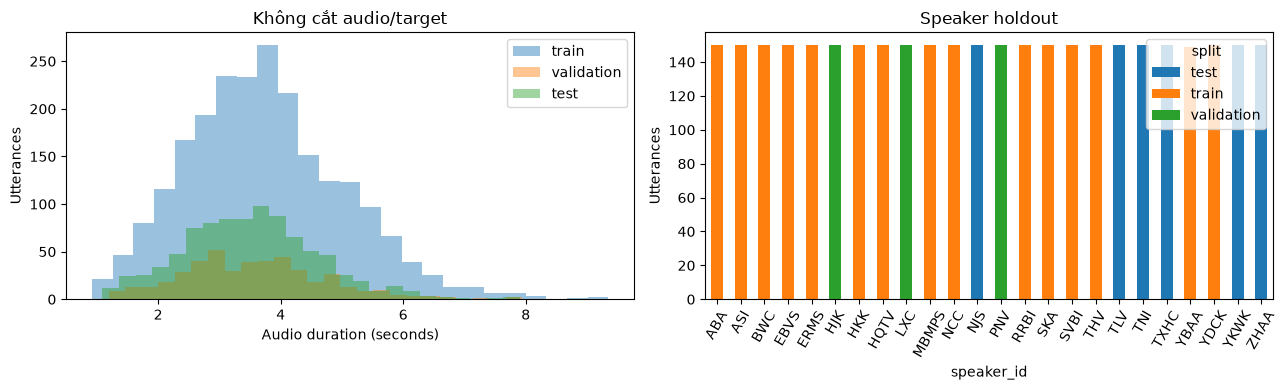

In [2]:
frames = {role: pd.DataFrame(rows) for role, rows in parts.items()}
display(pd.DataFrame([{'split': role, 'utterances': len(frame), 'speakers': frame.speaker_id.nunique(),
                      'audio_minutes': frame.duration_sec.sum()/60, 'median_seconds': frame.duration_sec.median()}
                     for role, frame in frames.items()]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for role, frame in frames.items():
    axes[0].hist(frame.duration_sec, bins=25, alpha=.45, label=role)
axes[0].set(xlabel='Audio duration (seconds)', ylabel='Utterances', title='Không cắt audio/target')
axes[0].legend()
pd.concat([frame.assign(split=role) for role, frame in frames.items()]).groupby(['speaker_id','split']).size().unstack(fill_value=0).plot.bar(stacked=True, ax=axes[1], rot=60)
axes[1].set(title='Speaker holdout', ylabel='Utterances')
fig.tight_layout()
REPORT.mkdir(parents=True, exist_ok=True)
fig.savefig(REPORT/'dataset_distribution.png', dpi=150)
plt.show()

## 2. Nghe một bản thu train và xem nhãn

Nhãn dưới đây dùng làm **target khi train/scorer khi test**; không được chèn vào prompt multimodal.

ABA/arctic_a0501 — You're joking me sir the other managed to articulate
Nguồn: authors_gpt4o_training_label


,word,issue,suggestion
0,joking,"""JH"" was replaced with ""ZH"", indicating a subs...","Practice the difference between /JH/ as in ""JO..."
1,joking,"An extra ""G"" sound was added, indicating an ad...","Focus on stopping after the /NG/ as in ""KING"" ..."
2,joking,"An extra ""AH"" sound was added, indicating an a...",Avoid adding extra vowel sounds after completi...
3,sir,"Unclear pronunciation, ""ER"" perceived with unc...","Practice /ER/ as in ""SIR"" (/S ER/) to add clarity"
4,other,"""DH"" was replaced with ""Z"", indicating a subst...","Practice unvoiced /DH/ as in ""THIS"" (/DH IH S/..."
5,other,"Unclear pronunciation, ""ER"" perceived with unc...","Practice /ER/ as in ""HER"" (/HH ER/) for more d..."
6,managed,"""JH"" was replaced with ""ZH"", indicating a subs...","Practice the distinction between /JH/ as in ""J..."
7,articulate,"""R"" was replaced with a foreign-accented ""R*"",...","Practice the American /R/ sound as in ""RED"" (/..."
8,articulate,"""EY"" was replaced with ""EH"", indicating a subs...","Practice the distinction between /EY/ as in ""D..."


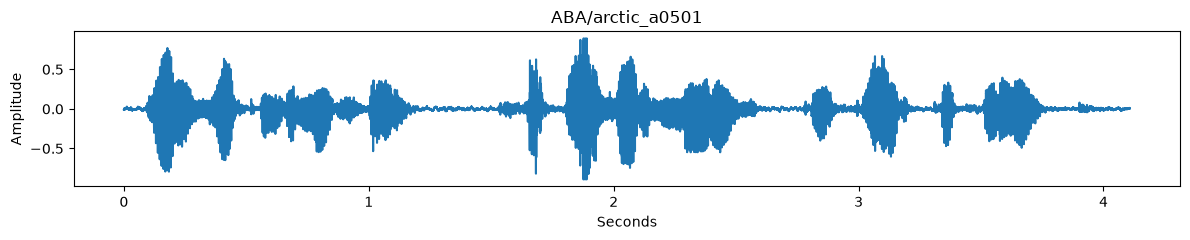

In [3]:
import soundfile as sf
example = parts['train'][0]
wave, rate = sf.read(ROOT/example['audio_path'])
print(example['utterance_id'], '—', example['reference_text'])
print('Nguồn:', example['feedback_provenance'])
display(Audio(wave.T, rate=rate))
display(pd.DataFrame([{'word': word, **pair} for word, pairs in example['feedback'].items() for pair in pairs]))
fig, ax = plt.subplots(figsize=(12, 2.5))
import numpy as np
ax.plot(np.arange(len(wave))/rate, wave)
ax.set(xlabel='Seconds', ylabel='Amplitude', title=example['utterance_id'])
fig.tight_layout()
plt.show()

## 3. Hai giai đoạn và cách ghép token

`text prefix embeddings | projected audio frames | text suffix embeddings | assistant target`

Loss chỉ tính trên assistant target; prompt/audio bị mask `-100`.
Qwen đóng băng ở giai đoạn 1 vẫn phải truyền gradient xuyên decoder về Projector.
Encoder B chạy CPU một lần để cache vector, giữ khoảng 50 frame/giây, không qua CTC/ASR trung gian.

In [4]:
display(pd.DataFrame([
    {'stage':'1 — alignment', 'input':'audio + yêu cầu transcribe (không có reference)', 'target':'transcript', 'wav2vec2 B':'frozen', 'Projector':'train 1,837,056 params', 'Qwen':'frozen', 'epochs':config['alignment']['epochs']},
    {'stage':'2 — feedback', 'input':'audio + reference sentence', 'target':'word → issue / suggestion JSON', 'wav2vec2 B':'frozen', 'Projector':'train', 'Qwen':'LoRA q_proj/v_proj rank 8', 'epochs':config['feedback']['epochs']}
]))
print('Projector: Linear(768,1024) → GELU → Linear(1024,1024)')
print('Training: NF4 Qwen, batch=1, accumulation=', config['gradient_accumulation_steps'], ', context=', config['max_length'])
print('Evaluation: cùng BF16/FP16, greedy, max_new_tokens=',config['generation']['max_new_tokens'])

,stage,input,target,wav2vec2 B,Projector,Qwen,epochs
0,1 — alignment,audio + yêu cầu transcribe (không có reference),transcript,frozen,"train 1,837,056 params",frozen,1
1,2 — feedback,audio + reference sentence,word → issue / suggestion JSON,frozen,train,LoRA q_proj/v_proj rank 8,3


Projector: Linear(768,1024) → GELU → Linear(1024,1024)
Training: NF4 Qwen, batch=1, accumulation= 8 , context= 3072
Evaluation: cùng BF16/FP16, greedy, max_new_tokens= 1536


## 4. Lệnh setup và chạy/resume

Môi trường `.venv` hiện tại đã có torch/transformers/peft/bitsandbytes. Không cần API key.
Runner chờ B hoàn tất, cache trên CPU, rồi đợi GPU lock của cascade.
Sau đó chạy stress test một update thật trên chuỗi dài nhất trước mỗi giai đoạn train.
Khi thiếu VRAM/lỗi, runner dừng và ghi log; không chuyển smoke thành điểm benchmark.

In [5]:
commands = [
    'scripts/run_projector_training.py --phase prepare',
    'scripts/run_projector_training.py --phase all',
    'scripts/run_projector_training.py --phase status',
    'scripts/report_projector.py'
]
for command in commands: print(str(PYTHON)+' -X utf8 '+command)

D:\NCC\MDD\.venv\Scripts\python.exe -X utf8 scripts/run_projector_training.py --phase prepare
D:\NCC\MDD\.venv\Scripts\python.exe -X utf8 scripts/run_projector_training.py --phase all
D:\NCC\MDD\.venv\Scripts\python.exe -X utf8 scripts/run_projector_training.py --phase status
D:\NCC\MDD\.venv\Scripts\python.exe -X utf8 scripts/report_projector.py


In [ ]:
RUN_PROJECTOR_TRAIN = False
if not RUN_PROJECTOR_TRAIN:
    print('Chỉ xem dữ liệu/trạng thái. Bạn tự bật cờ True khi muốn bắt đầu train.')
else:
    # CHẠY / RESUME: chỉ một runner, không chạy GPU song song với cascade.
    import psutil
    status_path = REPORT/'pipeline_status.json'
    state = read_json(status_path) if status_path.exists() else {}
    alive = psutil.pid_exists(state.get('pid', -1)) and state.get('status') not in ('completed', 'failed', 'report_ready')
    if alive:
        display(state)
    elif state.get('status') == 'completed':
        print('Nhánh Projector đã hoàn tất; xem report phía dưới.')
    else:
        with (REPORT/'pipeline-launch.log').open('a', encoding='utf-8') as log:
            process = subprocess.Popen([str(PYTHON), '-X', 'utf8', '-u', 'scripts/run_projector_training.py', '--phase', 'all'],
                cwd=ROOT, stdout=log, stderr=subprocess.STDOUT,
                creationflags=subprocess.CREATE_NO_WINDOW if os.name=='nt' else 0)
        print('Đã khởi chạy runner PID:', process.pid, '— GPU sẽ chờ cascade.')

## 5. Theo dõi tiến trình thật

Chạy lại cell này để cập nhật trạng thái. Đếm optimizer updates, không coi số lượt lấy mẫu là số file khác nhau.
`waiting_for_encoder_B` hoặc `waiting_for_gpu` nghĩa là nhánh mới đang xếp hàng, chưa train Projector.

In [6]:
for label, path in [('Projector', REPORT/'pipeline_status.json'),
                    ('Cascade', ROOT/'data/generated/cascade-l2arctic-plus-seed42/pipeline_status.json')]:
    print(label)
    display(read_json(path) if path.exists() else {'status':'not_started'})
for stage in ['alignment', 'feedback']:
    path = RUNS/stage/'progress.json'
    print(stage, read_json(path) if path.exists() else 'Chưa train')
feature_path = REPORT/'features/manifest.json'
if feature_path.exists():
    feature = read_json(feature_path)
    print('Feature cache:', feature['status'], len(feature['items']), '/', sum(manifest['counts'].values()))
    lengths = [item['shape'][0] for item in feature['items'].values()]
    if lengths:
        plt.hist(lengths, bins=30)
        plt.xlabel('Audio latent frames'); plt.ylabel('Utterances'); plt.show()

Projector

{'status': 'waiting_for_encoder_B',
 'pid': 23888,
 'started_at_utc': '2026-10-21T06:21:15.438037+00:00',
 'current_command': 'wait_B',
 'updated_at_utc': '2026-10-21T06:21:30.446603+00:00'}

Cascade


{'status': 'running',
 'phase': 'all',
 'started_at_utc': '2026-10-21T06:15:39.784709+00:00',
 'pid': 23960,
 'total_commands': 12,
 'command_index': 2,
 'current_command': 'train_B',
 'argv': ['D:\\NCC\\MDD\\.venv\\Scripts\\python.exe',
  '-X',
  'utf8',
  '-u',
  'scripts/train_mdd.py',
  '--config',
  'configs/cascade_adapt.json',
  '--runs-root',
  'runs\\cascade-l2arctic-plus-seed42',
  '--run-id',
  'B',
  '--init-checkpoint',
  'runs\\cascade-l2arctic-plus-seed42\\A\\best_checkpoint'],
 'log': 'D:\\NCC\\MDD\\data\\generated\\cascade-l2arctic-plus-seed42\\train_B.log',
 'updated_at_utc': '2026-10-21T06:21:34.069602+00:00',
 'child_pid': 17904}

alignment Chưa train
feedback Chưa train


## 6. Loss và thống kê trước/sau

**P0:** Projector đã học transcript, Qwen gốc; trước task tuning.
**P1:** Projector + LoRA sau task tuning. Cả hai dùng cùng B, audio và câu tham chiếu.
**B_Q1 cascade:** B sinh nhãn lỗi qua CTC rồi Qwen đã train nhận các nhãn đó.
Đây là so sánh hệ thống, không phải ablation cùng compute vì Projector có thêm alignment.

Report giữ output JSON lỗi trong mẫu số; không sửa bằng template.
Word-key F1, BLEU-2, ROUGE-L, NLL/perplexity và latency đánh giá phát hiện từ/độ giống nhãn.
Không diễn giải thành F1 âm vị hay chất lượng sư phạm do người đánh giá.
Bootstrap ghép cặp theo speaker cho delta ROUGE-L; một seed chưa đo độ ổn định qua nhiều lần train.

{'status': 'awaiting_evaluations',
 'counts': {'train': 2249, 'validation': 450, 'test': 900},
 'completed_cases': [],
 'scope': "P0 has transcript alignment only; P1 adds task training. Same frozen B encoder, speaker holdout and greedy decoding. Not a reproduction of the paper's larger models/data.",
 'metric_scope': 'Word-key detection and feedback lexical agreement, not phone-slot F1 or human-rated pedagogical quality.'}

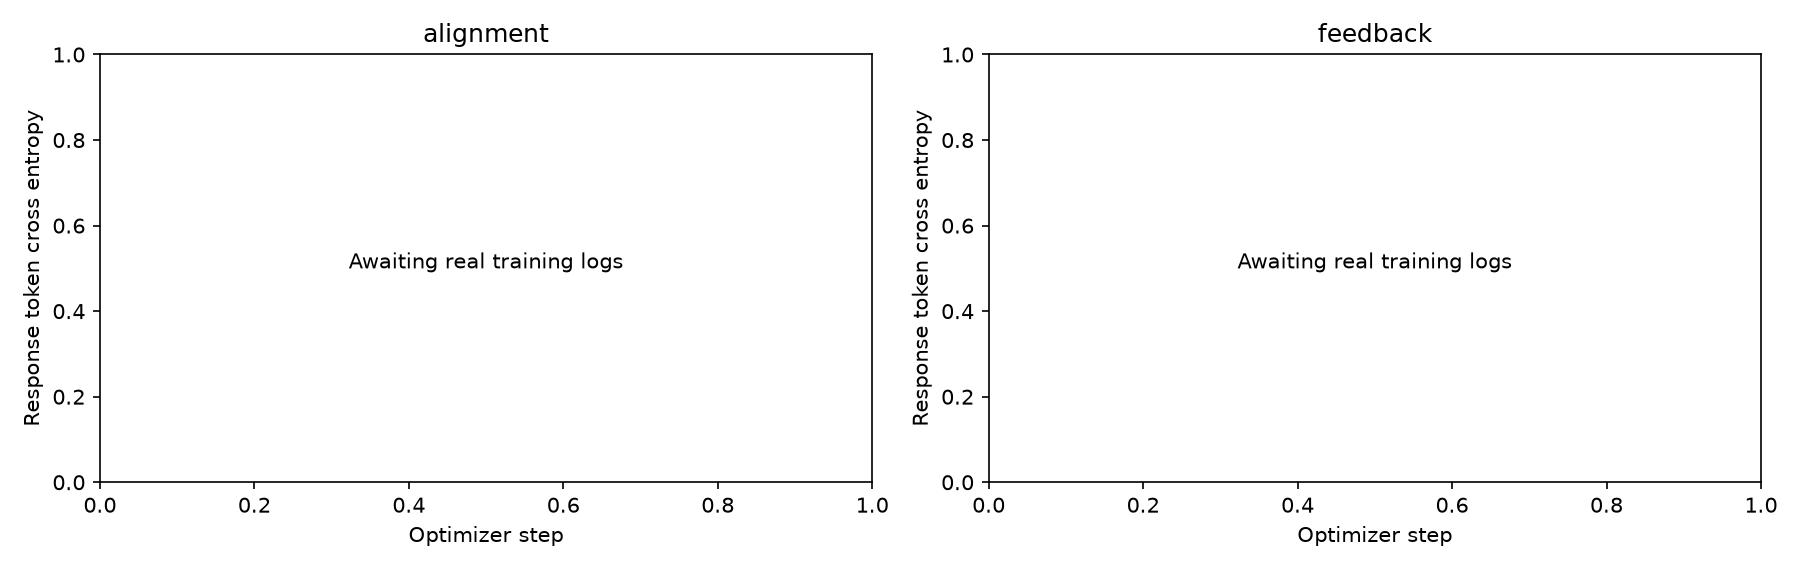

Chưa có kết quả trước/sau hoàn tất. Không suy ra điểm từ bài báo.
Report HTML: D:\NCC\MDD\data\generated\projector-l2arctic-plus-seed42\report\report.html


In [7]:
from scripts.report_projector import report
summary = report(config)
display(summary)
display(Image(filename=str(REPORT/'report/training_curves.png')))
csv = REPORT/'report/comparison.csv'
if summary['status']=='completed' and csv.exists():
    display(pd.read_csv(csv))
    display(Image(filename=str(REPORT/'report/comparison.png')))
    display(pd.read_csv(REPORT/'report/per_speaker.csv'))
else:
    print('Chưa có kết quả trước/sau hoàn tất. Không suy ra điểm từ bài báo.')
print('Report HTML:', REPORT/'report/report.html')

## 7. Kiểm thử

Chạy kiểm thử CPU riêng khi cần (không dùng GPU). Notebook và source giữ nguyên cascade đang train.

```powershell
.venv/Scripts/python.exe -X utf8 -m unittest tests.test_projector -v
```

Kết quả sau train chỉ xuất hiện khi đủ 900 test, checksum hợp lệ, cùng encoder và cùng cấu hình đánh giá.